# DOE-018
## ローカル高値・安値カウンタ基本評価
- 対象銘柄: 9984
- 実験パラメータ
    - TYPE_MA_1
        - EMA
    - PERIOD_MA_1
        - 30, 60, 90
    - PERIOD_MA_2
        - 900, 1200, 1500
    - FOLLOWING_MIN
        - 5, 10, 15
    - CONTRARIAN_MIN
        - 2, 5, 8
    - CONTRARIAN_MULT
        - 1, 2, 3
- MA1 / MA2 クロス・シグナルのエントリ・エグジット
- 評価指標
    - 収益と約定回数

In [1]:
from pathlib import Path

import pandas as pd

# === 実験番号 ===
name_doe = "doe-018"

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# 指定したディレクトリのPathオブジェクトを作成
dir_path = Path(f"../doe/{name_doe}")

# .glob() で .csv ファイルのリスト（イテレータ）を取得してリストに変換
list_csv_file = sorted([str(p) for p in dir_path.glob("*.csv") if p.is_file()])

# 集計対象の条件列
columns_group = [
    "TYPE_MA_1",
    "PERIOD_MA_1",
    "PERIOD_MA_2",
    "FOLLOWING_MIN",
    "CONTRARIAN_MIN",
    "CONTRARIAN_MULT",
]

# CSV ファイルを読み込んで結合
df = pd.concat(
    [pd.read_csv(file) for file in list_csv_file],
    ignore_index=True,
)

# 条件ごとに Profit を集計
df_total = df.groupby(columns_group, as_index=False).agg(
    Profit_Total=("Profit", "sum"),
    Profit_Median=("Profit", "median"),
    Transactions_Median=("Transactions", "median"),
)

print(df_total)
print("\n *** Past", len(list_csv_file), "days statistics ***")
print("\n△ Profit_Total Top 3")
print(df_total.nlargest(3, "Profit_Total"))
print("\n▼ Profit_Total Bottom 3")
print(df_total.nsmallest(3, "Profit_Total"))
print("\n\n△ Profit_Median Top 3")
print(df_total.nlargest(3, "Profit_Median"))
print("\n▼ Profit_Median Bottom 3")
print(df_total.nsmallest(3, "Profit_Median"))

    TYPE_MA_1  PERIOD_MA_1  PERIOD_MA_2  FOLLOWING_MIN  CONTRARIAN_MIN  CONTRARIAN_MULT  Profit_Total  Profit_Median  Transactions_Median
0         EMA           30          900              5               2                1       -2146.0         -100.0                 42.0
1         EMA           30          900              5               2                2       -1724.0          -76.0                 46.0
2         EMA           30          900              5               2                3       -1582.0          -70.0                 46.0
3         EMA           30          900              5               5                1       -1945.0         -106.0                 38.0
4         EMA           30          900              5               5                2       -1706.0          -76.5                 40.0
5         EMA           30          900              5               5                3       -1457.0          -62.0                 41.0
6         EMA           30        

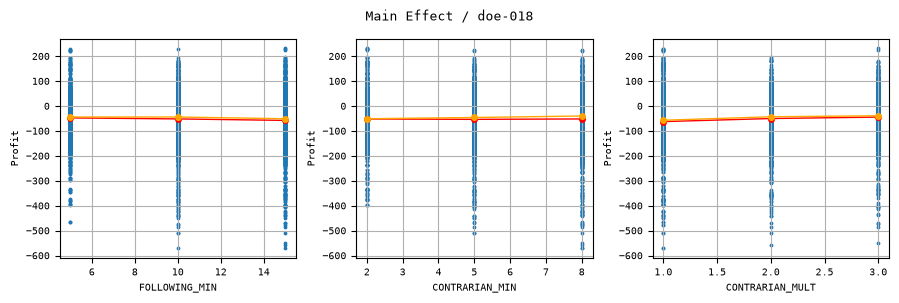

In [2]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "monospace"
plt.rcParams["font.size"] = 7

fig, axes = plt.subplots(1, 3, figsize=(9, 3))

cols_param = [
    "FOLLOWING_MIN",
    "CONTRARIAN_MIN",
    "CONTRARIAN_MULT",
]

name_y = "Profit"
for ax, col in zip(axes, cols_param):
    ax.scatter(df[col], df[name_y], s=3)

    # x の各水準ごとの平均値
    mean = df.groupby(col)[name_y].mean()
    # 平均値を線で結ぶ
    ax.plot(
        mean.index,
        mean.values,
        "o-",
        color="red",
        markersize=4,
        linewidth=1,
    )
    # x の各水準ごとのメジアン
    median = df.groupby(col)[name_y].median()
    # 平均値を線で結ぶ
    ax.plot(
        median.index,
        median.values,
        "o-",
        color="orange",
        markersize=4,
        linewidth=1,
    )
    
    ax.set(xlabel=col, ylabel=name_y)
    ax.grid(True)

fig.suptitle(f"Main Effect / {name_doe}", fontsize=9)

plt.tight_layout()
pngfile = f"../doe/{name_doe}/main_effect_{name_y}.png"
plt.savefig(pngfile)
plt.show()